In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import time
import os
import numpy as np

In [7]:
import math

### Build de EDA functions

In [2]:
def build_master_dataframe(directory_path):
    start_time = time.time()
    master_rows = []

    for filename in os.listdir(directory_path):
        if filename.endswith(".parquet"):
            file_path = os.path.join(directory_path, filename)
            df = pd.read_parquet(file_path)

            country_name = filename.split("_")[0]
            df = df[df["Year"] >= 2015].copy()
            df = df.ffill().bfill()

            # Eliminar columna 'house_price' si existe
            if "house_price" in df.columns:
                df.drop(columns=["house_price"], inplace=True)

            country_features = {"Country": country_name}
            macro_columns = [col for col in df.columns if col != "Year"]

            for col in macro_columns:
                series = df[col].values
                years = df["Year"].values.reshape(-1, 1)

                country_features[f"{col}_mean"] = np.mean(series)
                country_features[f"{col}_median"] = np.median(series)
                country_features[f"{col}_std"] = np.std(series)
                country_features[f"{col}_cv"] = np.std(series) / np.mean(series) if np.mean(series) != 0 else 0
                country_features[f"{col}_min"] = np.min(series)
                country_features[f"{col}_max"] = np.max(series)
                country_features[f"{col}_last"] = series[-1]
                country_features[f"{col}_growth"] = (series[-1] - series[0]) / series[0] if series[0] != 0 else 0

                if np.std(series) < 1e-8:
                    country_features[f"{col}_skew"] = 0
                    country_features[f"{col}_kurtosis"] = 0
                else:
                    country_features[f"{col}_skew"] = skew(series)
                    country_features[f"{col}_kurtosis"] = kurtosis(series)

                try:
                    model = LinearRegression().fit(years, series)
                    country_features[f"{col}_trend"] = model.coef_[0]
                except:
                    country_features[f"{col}_trend"] = np.nan

            master_rows.append(country_features)

    master_df = pd.DataFrame(master_rows)
    end_time = time.time()
    print(f"Time taken to perform feature engineering: {round(end_time - start_time, 2)} sec.")
    return master_df

In [3]:
def detect_outlier_columns(directory_path, year_threshold=2015, iqr_multiplier=1.5):
    outlier_report = {}

    for filename in os.listdir(directory_path):
        if filename.endswith(".parquet"):
            file_path = os.path.join(directory_path, filename)
            df = pd.read_parquet(file_path)

            country_name = filename.split("_")[0]
            df = df[df["Year"] >= year_threshold].copy()
            df = df.ffill().bfill()

            if "house_price" in df.columns:
                df.drop(columns=["house_price"], inplace=True)

            macro_columns = [col for col in df.columns if col != "Year"]
            outlier_cols = []

            for col in macro_columns:
                series = df[col].dropna()
                if len(series) < 5:
                    continue  # Evita columnas con pocos datos

                q1 = np.percentile(series, 25)
                q3 = np.percentile(series, 75)
                iqr = q3 - q1
                lower_bound = q1 - iqr_multiplier * iqr
                upper_bound = q3 + iqr_multiplier * iqr

                outliers = series[(series < lower_bound) | (series > upper_bound)]
                if len(outliers) > 0:
                    outlier_cols.append(col)

            outlier_report[country_name] = outlier_cols

    return outlier_report

In [4]:
detect_outlier_columns('../data/by_country/')

{'Australia': ['agr_land', 'inflation_df', 'govermment_effective_df'],
 'Austria': ['rule_of_law_df',
  'share_of_industry_df',
  'inflation_df',
  'govermment_effective_df'],
 'Belgium': ['agr_land',
  'share_of_industry_df',
  'tax_revenue_df',
  'inflation_df',
  'edu_spending_df'],
 'Brazil': ['inflation_df'],
 'Bulgaria': ['inflation_df'],
 'Canada': ['agr_land', 'unemployment', 'inflation_df'],
 'Chile': ['livestock_prod', 'inflation_df'],
 'Colombia': ['livestock_prod',
  'unemployment',
  'inflation_df',
  'edu_spending_df'],
 'Croatia': ['gov_exp',
  'reserves',
  'share_of_industry_df',
  'inflation_df',
  'edu_spending_df'],
 'Cyprus': ['agr_land', 'inflation_df'],
 'Czech': ['livestock_prod',
  'agr_land',
  'reserves',
  'unemployment',
  'inflation_df',
  'edu_spending_df'],
 'Denmark': ['livestock_prod', 'share_of_industry_df', 'inflation_df'],
 'Estonia': ['livestock_prod', 'agr_land', 'inflation_df', 'edu_spending_df'],
 'Finland': ['share_of_industry_df',
  'tax_reven

In [8]:
def plot_boxplot_grid_from_parquet(file_path, columns_to_plot, year_threshold=2015, cols_per_row=3):
    # Cargar y preparar el DataFrame
    df = pd.read_parquet(file_path)
    if "Year" in df.columns:
        df = df[df["Year"] >= year_threshold].copy()
    df = df.ffill().bfill()

    # Filtrar columnas válidas
    valid_columns = [col for col in columns_to_plot if col in df.columns and pd.api.types.is_numeric_dtype(df[col])]
    if not valid_columns:
        print("No hay columnas válidas para graficar.")
        return

    # Calcular disposición del grid
    total_plots = len(valid_columns)
    rows = math.ceil(total_plots / cols_per_row)

    # Crear figura
    fig, axes = plt.subplots(rows, cols_per_row, figsize=(cols_per_row * 4, rows * 4))
    axes = axes.flatten()  # Aplanar para indexar fácilmente

    for i, col in enumerate(valid_columns):
        axes[i].boxplot(df[col].dropna())
        axes[i].set_title(col)
        axes[i].tick_params(axis='x', labelrotation=45)

    # Ocultar ejes vacíos si sobran
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.suptitle("Boxplots por variable", fontsize=16, y=1.02)
    plt.show()


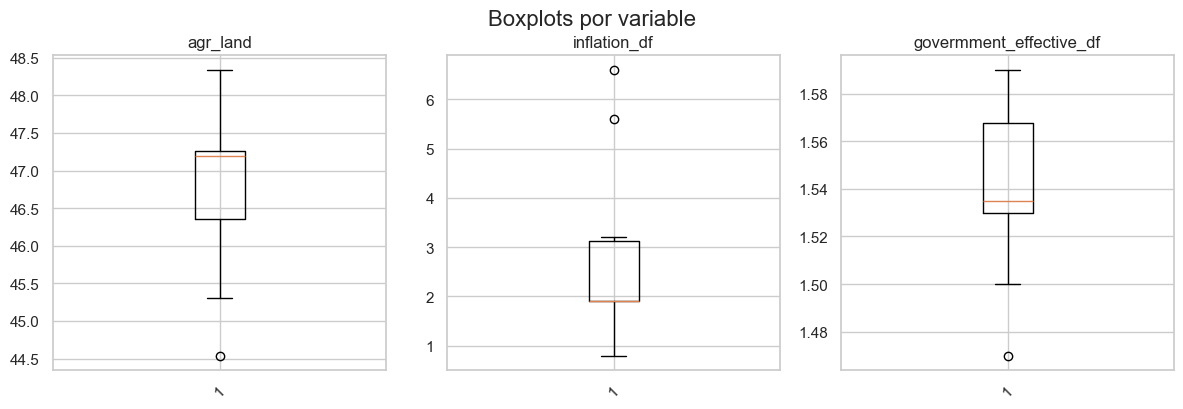

In [9]:
plot_boxplot_grid_from_parquet('../data/by_country/Australia_macro_profile.parquet', ['agr_land', 'inflation_df', 'govermment_effective_df'])

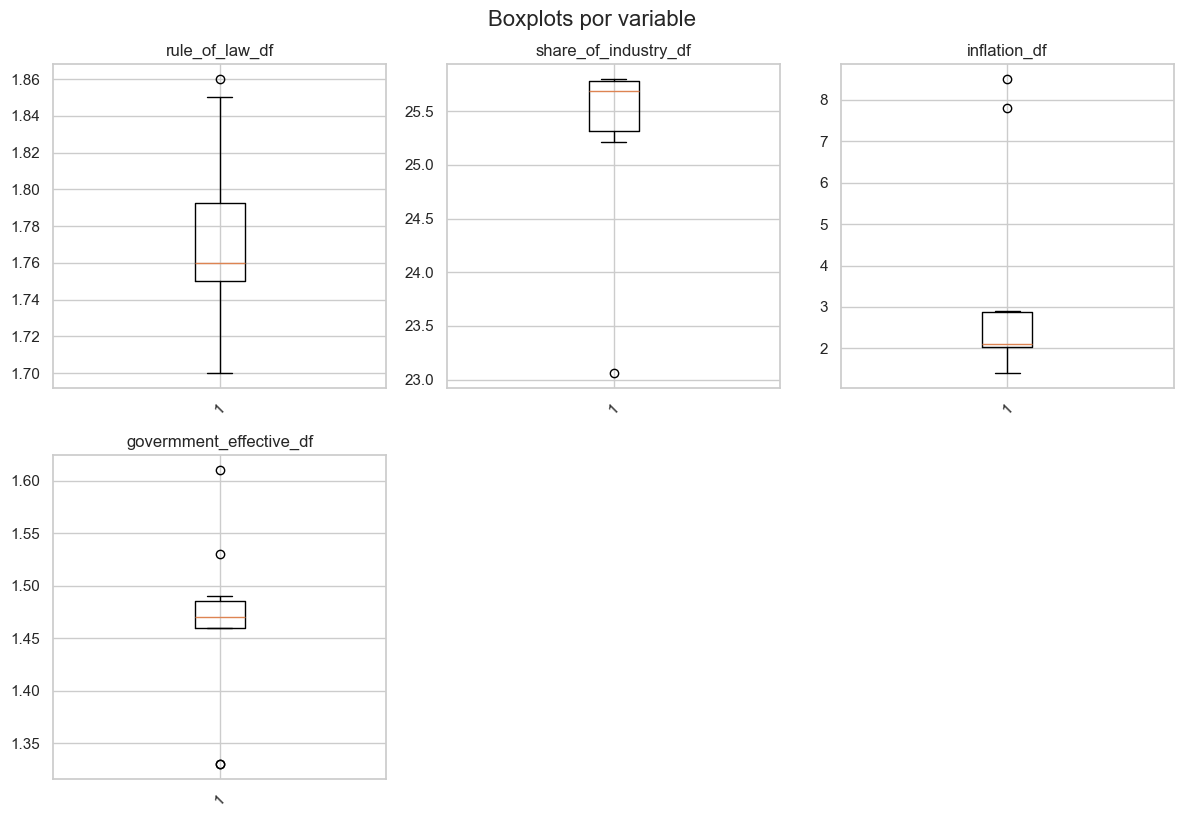

In [10]:
plot_boxplot_grid_from_parquet('../data/by_country/Austria_macro_profile.parquet', 
                               ['rule_of_law_df',
                                'share_of_industry_df',
                                'inflation_df',
                                'govermment_effective_df'])

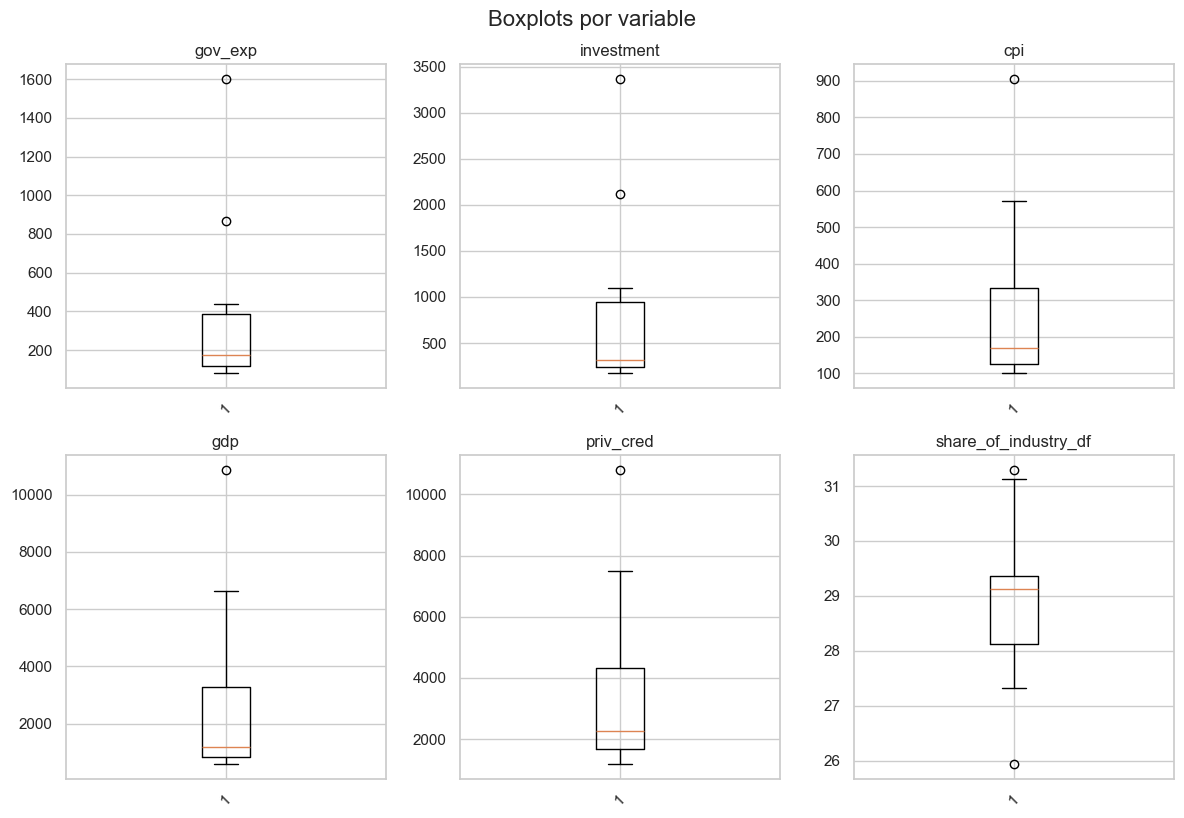

In [11]:
plot_boxplot_grid_from_parquet('../data/by_country/Turkey_macro_profile.parquet', 
                               ['gov_exp',
                                'investment',
                                'cpi',
                                'gdp',
                                'priv_cred',
                                'share_of_industry_df'])

### Work over outliers before summarize in one point the countries

In [18]:
from collections import Counter

In [16]:
def check_remaining_outliers(dataframes_dict, iqr_multiplier=1.5):
    outlier_check_report = {}

    for country, df in dataframes_dict.items():
        outlier_columns = []

        macro_columns = [col for col in df.columns if col != "Year" and pd.api.types.is_numeric_dtype(df[col])]
        for col in macro_columns:
            series = df[col].dropna()
            if len(series) < 5:
                continue  # Evita columnas con pocos datos

            q1 = np.percentile(series, 25)
            q3 = np.percentile(series, 75)
            iqr = q3 - q1
            lower_bound = q1 - iqr_multiplier * iqr
            upper_bound = q3 + iqr_multiplier * iqr

            outliers = series[(series < lower_bound) | (series > upper_bound)]
            if len(outliers) > 0:
                outlier_columns.append(col)

        if outlier_columns:
            outlier_check_report[country] = outlier_columns

    return outlier_check_report

In [44]:
def rank_outlier_variables(outlier_dict, exclude_columns={"Year"}):
    counter = Counter()
    for macro_list in outlier_dict.values():
        filtered_macros = [col for col in macro_list if col not in exclude_columns]
        counter.update(filtered_macros)

    sorted_macros = sorted(counter.items(), key=lambda x: x[1], reverse=True)

    print("📊 Ranking de macroeconómicos con outliers (por número de países):\n")
    for macro, count in sorted_macros:
        print(f"{macro}: {count} países")

In [47]:
def adaptive_winsorize(series, iqr_multiplier=2.0):
    q1 = np.percentile(series, 25)
    q3 = np.percentile(series, 75)
    iqr = q3 - q1
    lower = q1 - iqr_multiplier * iqr
    upper = q3 + iqr_multiplier * iqr
    return np.clip(series, lower, upper)

def preprocess_parquets_with_log_and_winsorization(directory_path, year_threshold=2015):
    # Variables recomendadas para log transform
    log_variables = {
        "inflation_df",
        "edu_spending_df",
        "livestock_prod",
        "tax_revenue_df",
        "reserves",
        "labor_force",
        "priv_cred",
        "cpi",
        "gov_exp",
        "investment",
        "gdp"
    }

    processed_dataframes = {}

    for filename in os.listdir(directory_path):
        if filename.endswith(".parquet"):
            file_path = os.path.join(directory_path, filename)
            df = pd.read_parquet(file_path)

            # Filtrar años y rellenar vacíos
            if "Year" in df.columns:
                df = df[df["Year"] >= year_threshold].copy()
            df = df.ffill().bfill()

            # Aplicar log transform solo a variables recomendadas
            for col in df.columns:
                if col in log_variables and pd.api.types.is_numeric_dtype(df[col]):
                    df[col] = df[col].apply(lambda x: np.nan if x <= 0 else np.log1p(x))

            # Aplicar winsorización adaptativa a todas las columnas numéricas
            for col in df.columns:
                if col != "Year" and pd.api.types.is_numeric_dtype(df[col]):
                    df[col] = adaptive_winsorize(df[col])

            # Extraer nombre del país desde el nombre del archivo
            country_name = filename.split("_")[0]
            processed_dataframes[country_name] = df

    return processed_dataframes

In [48]:
def iterative_winsorization(dataframes_dict, max_iterations=10, iqr_multiplier=2.0):
    current_data = {country: df.copy() for country, df in dataframes_dict.items()}
    for iteration in range(max_iterations):
        outliers = check_remaining_outliers(current_data, iqr_multiplier)
        if not outliers:
            print(f"✅ No se detectan outliers después de {iteration} iteraciones.")
            break
        print(f"🔁 Iteración {iteration + 1}: {sum(len(v) for v in outliers.values())} columnas con outliers.")
        for country, cols in outliers.items():
            for col in cols:
                if col in current_data[country].columns:
                    current_data[country][col] = adaptive_winsorize(current_data[country][col], iqr_multiplier)
    else:
        print(f"⚠️ Se alcanzó el máximo de {max_iterations} iteraciones. Puede que aún queden outliers.")
    return current_data

In [49]:
processed_dataframes = preprocess_parquets_with_log_and_winsorization('../data/by_country/')

In [50]:
rank_outlier_variables(processed_dataframes)

📊 Ranking de macroeconómicos con outliers (por número de países):

labor_force: 52 países
livestock_prod: 52 países
agr_land: 52 países
urban_pop: 52 países
gov_exp: 52 países
reserves: 52 países
investment: 52 países
cpi: 52 países
gdp: 52 países
priv_cred: 52 países
unemployment: 52 países
house_price: 52 países
rule_of_law_df: 52 países
share_of_industry_df: 52 países
tax_revenue_df: 52 países
inflation_df: 52 países
edu_spending_df: 52 países
govermment_effective_df: 52 países


In [41]:
check_remaining_outliers(processed_dataframes)

{'Australia': ['agr_land', 'inflation_df', 'govermment_effective_df'],
 'Austria': ['rule_of_law_df',
  'share_of_industry_df',
  'inflation_df',
  'govermment_effective_df'],
 'Belgium': ['agr_land',
  'share_of_industry_df',
  'tax_revenue_df',
  'inflation_df',
  'edu_spending_df'],
 'Brazil': ['inflation_df'],
 'Bulgaria': ['inflation_df'],
 'Canada': ['agr_land', 'unemployment'],
 'Chile': ['livestock_prod', 'inflation_df'],
 'Colombia': ['livestock_prod', 'unemployment', 'edu_spending_df'],
 'Croatia': ['reserves',
  'share_of_industry_df',
  'inflation_df',
  'edu_spending_df'],
 'Cyprus': ['agr_land', 'house_price'],
 'Czech': ['livestock_prod',
  'agr_land',
  'reserves',
  'unemployment',
  'inflation_df',
  'edu_spending_df'],
 'Denmark': ['livestock_prod', 'share_of_industry_df', 'inflation_df'],
 'Estonia': ['livestock_prod', 'agr_land', 'inflation_df', 'edu_spending_df'],
 'Finland': ['investment',
  'house_price',
  'share_of_industry_df',
  'tax_revenue_df',
  'inflatio

In [51]:
processed_dataframes['Chile']

,Year,labor_force,livestock_prod,agr_land,urban_pop,gov_exp,reserves,investment,cpi,gdp,priv_cred,unemployment,house_price,rule_of_law_df,share_of_industry_df,tax_revenue_df,inflation_df,edu_spending_df,govermment_effective_df
8,2015,2.278292,4.620059,17.52,87.42,8.592496,3.677692,9.220435,4.250743,10.588016,11.709060,6.647500,174.9375,0.96,27.86,2.920470,1.163151,1.774952,0.83
9,2016,2.278292,4.619073,17.00,87.42,8.708200,3.699387,9.228317,4.287372,10.649990,11.797795,6.647500,186.4325,0.96,27.86,2.916148,1.163151,1.851599,0.83
10,2017,2.299581,4.577799,16.55,87.49,8.789939,3.685917,9.208221,4.308660,10.710627,11.854026,6.935000,201.6525,0.98,27.86,2.918311,1.163151,1.860975,0.81
11,2018,2.318458,4.632785,15.99,87.56,8.858914,3.661808,9.298084,4.332410,10.765527,11.930654,7.334167,221.8375,0.94,27.12,2.965273,1.223775,1.867176,0.91
12,2019,2.333114,4.639572,15.42,87.64,8.916987,3.690420,9.392796,4.357328,10.797204,12.017499,7.216667,240.5325,0.92,29.83,2.929592,1.280934,1.891605,0.86
13,2020,2.293544,4.682131,14.89,87.73,8.995236,3.648903,9.337410,4.386983,10.826067,12.105829,10.574167,256.5100,0.93,30.86,2.844909,1.386294,1.891605,0.71
14,2021,2.319442,4.670021,14.55,87.82,9.084998,3.878018,9.544126,4.430668,10.999689,12.149597,9.112500,286.8875,0.89,31.03,3.028199,1.704748,1.791759,0.59
15,2022,2.367436,4.648230,14.31,87.91,9.178341,3.809843,9.733032,4.539564,11.093879,12.257715,7.800000,306.6625,0.69,28.80,3.103240,2.533697,1.791759,0.55
16,2023,2.394252,4.648230,14.31,88.01,9.285595,3.738027,9.745912,4.611889,11.162877,12.305209,8.642500,331.2325,0.63,30.09,3.103240,2.151762,1.791759,0.72
17,2024,2.394252,4.648230,14.31,88.01,9.370725,3.836743,9.814712,4.653254,11.263293,12.334700,8.642500,354.5200,0.63,30.09,3.103240,1.667707,1.791759,0.72


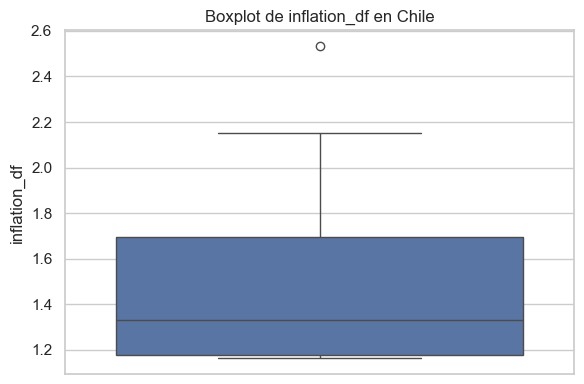

In [52]:
# Seleccionar el DataFrame del país
df_chile = processed_dataframes["Chile"]

# Seleccionar la variable macroeconómica
macro = "inflation_df"

# Crear el boxplot
plt.figure(figsize=(6, 4))
sns.boxplot(y=df_chile[macro])
plt.title(f"Boxplot de {macro} en Chile")
plt.ylabel(macro)
plt.tight_layout()
plt.show()

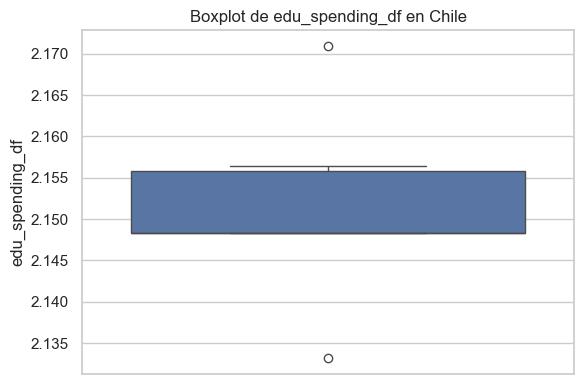

In [53]:
# Seleccionar el DataFrame del país
df_chile = processed_dataframes["Sweden"]

# Seleccionar la variable macroeconómica
macro = "edu_spending_df"

# Crear el boxplot
plt.figure(figsize=(6, 4))
sns.boxplot(y=df_chile[macro])
plt.title(f"Boxplot de {macro} en Chile")
plt.ylabel(macro)
plt.tight_layout()
plt.show()

### Convert in one point data the countries

In [54]:
import time
from scipy.stats import skew, kurtosis
from sklearn.linear_model import LinearRegression

In [55]:
def build_master_dataframe_from_dict(dataframes_dict):
    start_time = time.time()
    master_rows = []

    for country_name, df in dataframes_dict.items():
        df = df[df["Year"] >= 2015].copy()
        df = df.ffill().bfill()

        # Eliminar columna 'house_price' si existe
        if "house_price" in df.columns:
            df.drop(columns=["house_price"], inplace=True)

        country_features = {"Country": country_name}
        macro_columns = [col for col in df.columns if col != "Year"]

        for col in macro_columns:
            series = df[col].values
            years = df["Year"].values.reshape(-1, 1)

            country_features[f"{col}_mean"] = np.mean(series)
            country_features[f"{col}_median"] = np.median(series)
            country_features[f"{col}_std"] = np.std(series)
            country_features[f"{col}_cv"] = np.std(series) / np.mean(series) if np.mean(series) != 0 else 0
            country_features[f"{col}_min"] = np.min(series)
            country_features[f"{col}_max"] = np.max(series)
            country_features[f"{col}_last"] = series[-1]
            country_features[f"{col}_growth"] = (series[-1] - series[0]) / series[0] if series[0] != 0 else 0

            if np.std(series) < 1e-8:
                country_features[f"{col}_skew"] = 0
                country_features[f"{col}_kurtosis"] = 0
            else:
                country_features[f"{col}_skew"] = skew(series)
                country_features[f"{col}_kurtosis"] = kurtosis(series)

            try:
                model = LinearRegression().fit(years, series)
                country_features[f"{col}_trend"] = model.coef_[0]
            except:
                country_features[f"{col}_trend"] = np.nan

        master_rows.append(country_features)

    master_df = pd.DataFrame(master_rows)
    end_time = time.time()
    print(f"Time taken to perform feature engineering: {round(end_time - start_time, 2)} sec.")
    return master_df

In [56]:
master_df = build_master_dataframe_from_dict(final_dataframes)

Time taken to perform feature engineering: 1.37 sec.


In [57]:
master_df

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_cv,labor_force_min,labor_force_max,labor_force_last,labor_force_growth,labor_force_skew,...,govermment_effective_df_median,govermment_effective_df_std,govermment_effective_df_cv,govermment_effective_df_min,govermment_effective_df_max,govermment_effective_df_last,govermment_effective_df_growth,govermment_effective_df_skew,govermment_effective_df_kurtosis,govermment_effective_df_trend
0,Australia,2.678890,2.679994,0.042374,0.015818,2.619583,2.740840,2.740840,0.046289,0.046350,...,1.535,0.036180,2.347833e-02,1.4700,1.590,1.590,0.039216,-0.346877,-0.627720,0.005273
1,Austria,1.736643,1.731654,0.016233,0.009347,1.717395,1.763017,1.763017,0.026565,0.515156,...,1.470,0.039525,2.687882e-02,1.4100,1.535,1.410,-0.040816,0.066706,-0.672530,-0.004576
2,Belgium,1.825060,1.821317,0.024303,0.013317,1.791759,1.859418,1.859418,0.037761,0.121315,...,1.165,0.129016,1.088738e-01,1.0400,1.400,1.040,-0.257143,0.542175,-1.048411,-0.037758
3,Brazil,4.651135,4.653483,0.021975,0.004725,4.612046,4.675629,4.673763,0.010121,-0.392741,...,-0.480,0.135632,-3.214025e-01,-0.5900,-0.230,-0.550,1.200000,0.321185,-1.620024,-0.038182
4,Bulgaria,1.447840,1.451614,0.022617,0.015621,1.408545,1.477049,1.408545,-0.029670,-0.654102,...,0.070,0.146969,-5.295130e+16,-0.2700,0.170,0.050,-0.444444,-0.794950,-1.012397,-0.022303
5,Canada,3.081890,3.073828,0.036273,0.011770,3.038792,3.141563,3.141563,0.033820,0.510275,...,1.640,0.099524,6.050083e-02,1.5200,1.820,1.520,-0.126437,0.228245,-1.279805,-0.031697
6,Chile,2.327667,2.318950,0.041785,0.017951,2.278292,2.394252,2.394252,0.050898,0.479126,...,0.765,0.110910,1.472907e-01,0.5500,0.910,0.720,-0.132530,-0.487748,-0.865772,-0.025273
7,Colombia,3.263395,3.260973,0.032584,0.009985,3.217675,3.306520,3.306520,0.027612,-0.051684,...,-0.110,0.064969,-7.827617e-01,-0.1400,0.010,-0.080,-0.428571,0.542294,-1.444192,0.014000
8,Croatia,1.010808,1.007958,0.011442,0.011320,0.996949,1.029619,1.007958,-0.021038,0.652768,...,0.525,0.104575,1.965702e-01,0.4200,0.710,0.710,0.690476,0.594399,-0.899318,0.029818
9,Cyprus,0.523890,0.521761,0.022211,0.042397,0.494696,0.553885,0.553885,0.119647,0.060286,...,0.860,0.092758,1.112203e-01,0.7000,0.960,0.740,-0.204301,-0.143984,-1.606241,-0.027273


### Because the presence of outliers continue use robust scaler

In [58]:
from sklearn.preprocessing import RobustScaler

In [59]:
def scale_master_dataframe_robust(master_df):
    # Separar columna de país
    country_column = master_df["Country"]
    
    # Seleccionar solo columnas numéricas
    numeric_df = master_df.drop(columns=["Country"])
    
    # Aplicar RobustScaler
    scaler = RobustScaler()
    scaled_array = scaler.fit_transform(numeric_df)
    
    # Reconstruir DataFrame escalado
    scaled_df = pd.DataFrame(scaled_array, columns=numeric_df.columns)
    scaled_df.insert(0, "Country", country_column.values)
    
    return scaled_df

In [60]:
scaled_master_df = scale_master_dataframe_robust(master_df)

In [61]:
scaled_master_df

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_cv,labor_force_min,labor_force_max,labor_force_last,labor_force_growth,labor_force_skew,...,govermment_effective_df_median,govermment_effective_df_std,govermment_effective_df_cv,govermment_effective_df_min,govermment_effective_df_max,govermment_effective_df_last,govermment_effective_df_growth,govermment_effective_df_skew,govermment_effective_df_kurtosis,govermment_effective_df_trend
0,Australia,0.294383,0.290522,0.979990,0.462827,0.286071,0.304399,0.317782,0.635448,-0.161546,...,0.420513,-1.087629,-4.953386e-01,0.452830,0.438479,0.439771,0.214683,-0.581632,1.074842,0.353061
1,Austria,-0.165386,-0.174302,-0.194594,-0.184313,-0.151772,-0.171715,-0.149126,0.046106,0.449494,...,0.367179,-1.030585,-4.635524e-01,0.402516,0.389262,0.302103,0.006573,0.252592,0.996728,0.131973
2,Belgium,-0.122243,-0.130354,0.168033,0.212662,-0.115682,-0.124776,-0.103095,0.380648,-0.063836,...,0.116923,0.495441,3.028990e-01,0.092243,0.268456,0.019120,-0.555949,1.211643,0.341490,-0.612925
3,Brazil,1.256740,1.257817,0.063405,-0.646626,1.253039,1.246472,1.240748,-0.445208,-0.733854,...,-1.232821,0.608266,-3.719125e+00,-1.274633,-1.190157,-1.196941,3.233113,0.765893,-0.654951,-0.622449
4,Bulgaria,-0.306307,-0.311562,0.092278,0.443186,-0.301661,-0.310956,-0.318386,-1.634147,-1.074512,...,-0.781538,0.801598,-4.949642e+17,-1.006289,-0.832215,-0.738050,-1.042997,-1.485425,0.404269,-0.265986
5,Canada,0.491027,0.483558,0.705826,0.057951,0.489518,0.499516,0.509126,0.262883,0.443133,...,0.506667,-0.007463,-1.492695e-01,0.494759,0.644295,0.386233,-0.216069,0.578426,-0.061879,-0.476871
6,Chile,0.123004,0.113559,0.953506,0.676206,0.120438,0.135642,0.152287,0.773167,0.402533,...,-0.211282,0.186696,6.620017e-01,-0.318658,-0.170022,-0.225621,-0.231914,-0.865779,0.659868,-0.332653
7,Colombia,0.579592,0.575286,0.540091,-0.120559,0.576333,0.579836,0.587893,0.077389,-0.289323,...,-0.929231,-0.596704,-8.031697e+00,-0.897275,-0.975391,-0.837476,-1.001721,1.211883,-0.348440,0.548980
8,Croatia,-0.519557,-0.529017,-0.409853,0.012951,-0.501414,-0.528815,-0.509665,-1.376248,0.628858,...,-0.408205,0.078676,1.122644e+00,-0.427673,-0.348993,-0.233270,1.908180,1.316983,0.601389,0.904082
9,Cyprus,-0.757149,-0.767324,0.074029,3.121024,-0.745163,-0.760456,-0.726483,2.827359,-0.143381,...,-0.133333,-0.122842,3.248328e-01,-0.192872,-0.125280,-0.210325,-0.418543,-0.172384,-0.630924,-0.377551


In [ ]:
scaled_master_df.to_parquet('../data/log_win_transform_then_one_point_countries_ready_for_clust_and_pca.parquet')